In [1]:
import matplotlib.pyplot as plt

%matplotlib inline

# plt.plot([1, 2, 3], [1, 4, 9], label="B torch")
import torch

# plt.plot([1, 2, 3], [1, 4, 9], label="A torch")
# plt.legend()

import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

# plt.plot([1, 2, 3], [1, 4, 9], label="B torchvistion")
from torchvision import datasets, transforms, models  # add model to the list
# plt.plot([1, 2, 3], [1, 4, 9], label="A torchvistion")
# plt.legend()

from torchvision.utils import make_grid

import os


import numpy as np
import pandas as pd


import warnings

warnings.filterwarnings("ignore")

In [2]:
import torch

print(torch.__version__)

import matplotlib

matplotlib.use("Agg")

import matplotlib.pyplot as plt
import numpy as np

plt.imshow(np.random.rand(100, 100, 3))
plt.savefig("test.png")

print("Plot saved successfully")

1.12.1+cpu
Plot saved successfully


In [3]:
import torch

print("1 - Torch OK", torch.__version__, flush=True)

1 - Torch OK 1.12.1+cpu


In [4]:
import matplotlib

print("2 - Matplotlib OK", matplotlib.__version__, flush=True)

2 - Matplotlib OK 3.5.3


In [5]:
matplotlib.use("Agg")
print("3 - Backend OK", flush=True)

3 - Backend OK


In [6]:
import matplotlib.pyplot as plt

print("4 - Pyplot OK", flush=True)

4 - Pyplot OK


In [7]:
import numpy as np

plt.imshow(np.random.rand(100, 100, 3))
plt.savefig("test.png")

print("5 - Plot OK", flush=True)

5 - Plot OK


In [8]:
plt.plot([1, 2, 3], [1, 4, 9])

In [9]:
import matplotlib

print("Backend:", matplotlib.get_backend())

import matplotlib.pyplot as plt

print("Pyplot imported")

import numpy as np

print("NumPy imported")

x = np.random.rand(100, 100, 3)
print("Array created")

plt.figure()
print("Figure created")

plt.imshow(x)
print("Image displayed")

plt.show()
print("Show completed")

Backend: agg
Pyplot imported
NumPy imported
Array created
Figure created
Image displayed
Show completed


c:\Users\rtajik\anaconda3\envs\pytorchenv\python.exe
Matplotlib: 3.5.3
Backend: agg


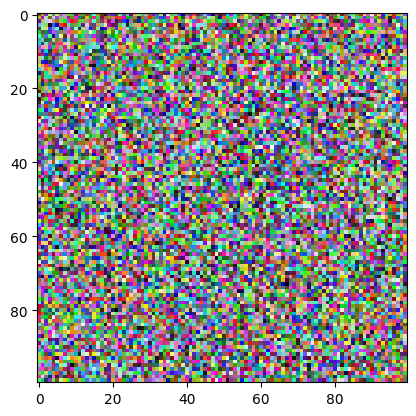

In [10]:
import sys

print(sys.executable)

import matplotlib

print("Matplotlib:", matplotlib.__version__)
print("Backend:", matplotlib.get_backend())

import matplotlib.pyplot as plt

%matplotlib inline
import numpy as np

plt.imshow(np.random.rand(100, 100, 3))
plt.show()

In [11]:
# import sys
# print(sys.executable)

# import matplotlib.pyplot as plt
# import numpy as np

# plt.imshow(np.random.rand(100, 100, 3))
# plt.show()

In [12]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose(
    [
        transforms.RandomRotation(10),
        transforms.RandomHorizontalFlip(),
        transforms.Resize(224),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ]
)

test_transform = transforms.Compose(
    [
        transforms.Resize(224),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ]
)

In [ ]:
root = "./Data/CATS_DOGS"

train_data = datasets.ImageFolder(
    os.path.join(root, "train"), transform=train_transform
)
test_data = datasets.ImageFolder(os.path.join(root, "test"), transform=test_transform)

In [14]:
# torch.manual_seed(42)
batch_size = 10

train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)


In [15]:
class_name = np.array(train_data.classes)
class_name

array(['CAT', 'DOG'], dtype='<U3')

In [16]:
len(test_data)

6251

In [17]:
for images, labels in train_loader:
    break

In [18]:
images.shape

torch.Size([10, 3, 224, 224])

LABELS:  ['DOG' 'CAT' 'DOG' 'DOG' 'DOG' 'CAT' 'CAT' 'DOG' 'CAT' 'CAT']


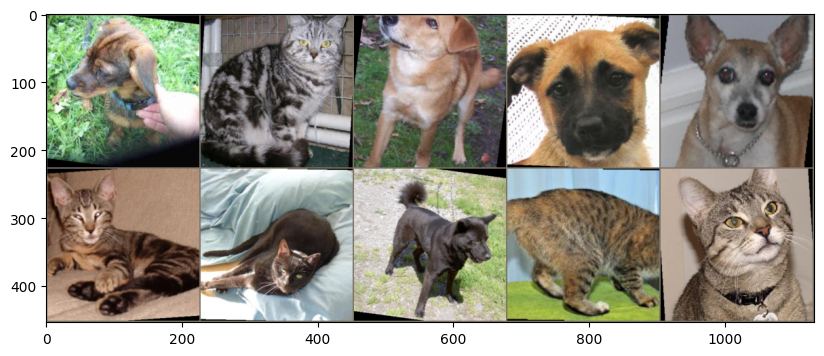

In [19]:
im = make_grid(images, nrow=5)
mean_inv = [-m / s for m, s in zip(mean, std)]
std_inv = [1 / s for s in std]

inv_normalize = transforms.Normalize(mean=mean_inv, std=std_inv)

im_inv = inv_normalize(im)

print("LABELS: ", class_name[labels])
plt.figure(figsize=(12, 4))
plt.imshow(im_inv.permute(1, 2, 0))

In [20]:
class ConvolutionaNetwork_CATS_DOGS(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 3)
        self.conv2 = nn.Conv2d(6, 16, 3)
        self.fc1 = nn.Linear(54 * 54 * 16, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 2)

    def forward(self, X):
        X = F.relu(self.conv1(X))
        X = F.max_pool2d(X, 2, 2)
        X = F.relu(self.conv2(X))
        X = F.max_pool2d(X, 2, 2)
        X = X.view(len(X), -1)
        X = F.relu(self.fc1(X))
        X = F.relu(self.fc2(X))
        X = self.fc3(X)

        return X

In [21]:
class ConvolutionaNetwork2(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 3)
        self.conv2 = nn.Conv2d(6, 16, 3)
        self.conv3 = nn.Conv2d(16, 26, 3)
        self.conv4 = nn.Conv2d(26, 36, 3)
        self.fc1 = nn.Linear(12 * 12 * 36, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 2)

    def forward(self, X):
        X = F.relu(self.conv1(X))
        X = F.max_pool2d(X, 2, 2)
        X = F.relu(self.conv2(X))
        X = F.max_pool2d(X, 2, 2)
        X = F.relu(self.conv3(X))
        X = F.max_pool2d(X, 2, 2)
        X = F.relu(self.conv4(X))
        X = F.max_pool2d(X, 2, 2)
        X = X.view(len(X), -1)
        X = F.relu(self.fc1(X))
        X = F.relu(self.fc2(X))
        X = self.fc3(X)

        return X

In [22]:
((54 - 2) / 2 - 2) / 2

12.0

In [23]:
torch.manual_seed(101)

CNNmodel = ConvolutionaNetwork_CATS_DOGS()
criterion = nn.CrossEntropyLoss()
optimizers = torch.optim.Adam(CNNmodel.parameters(), lr=0.001)
CNNmodel

ConvolutionaNetwork_CATS_DOGS(
  (conv1): Conv2d(3, 6, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=46656, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=2, bias=True)
)

In [24]:
total = 0

for name, param in CNNmodel.named_parameters():
    print(name, param.shape)
    total += param.numel()

print(total)

conv1.weight torch.Size([6, 3, 3, 3])
conv1.bias torch.Size([6])
conv2.weight torch.Size([16, 6, 3, 3])
conv2.bias torch.Size([16])
fc1.weight torch.Size([120, 46656])
fc1.bias torch.Size([120])
fc2.weight torch.Size([84, 120])
fc2.bias torch.Size([84])
fc3.weight torch.Size([2, 84])
fc3.bias torch.Size([2])
5610222


In [25]:
import time

start_time = time.time()

# Limits on num of batches
max_trn_batch = 800  # batch 10 images --> 8000 images
max_tst_batch = 300  # 3000 max images


# variables
epochs = 10
train_losses = []
test_losses = []
train_correct = []
test_correct = []

# For loop epochs
for i in range(epochs):
    trn_corr = 0
    tst_corr = 0

    # train
    for b, (X_train, y_train) in enumerate(train_loader):
        # Optinal limit number of batch
        # if b == max_trn_batch:
        #     break

        b += 1

        y_pred = CNNmodel(X_train)  # no flatten
        loss = criterion(y_pred, y_train)
        predicted = torch.max(y_pred.data, 1)[1]
        trn_corr += (predicted == y_train).sum()

        optimizers.zero_grad()
        loss.backward()
        optimizers.step()

        if b % 200 == 0:
            acc = trn_corr * 100 / len(X_train) / b
            print(
                f"Epoch: {i + 1:2} Batch: {b:4} [{len(X_train) * b}/{len(train_data)}] loss: {loss.item():2.8f} accuracy: {acc:2.2f}%"
            )

    train_losses.append(loss.item())
    train_correct.append(trn_corr)

    # validation
    with torch.no_grad():
        for b, (X_test, y_test) in enumerate(test_loader):
            # if b == max_tst_batch:
            #     break
            y_val = CNNmodel(X_test)
            predicted = torch.max(y_val.data, 1)[1]
            tst_corr += (predicted == y_test).sum()

    loss = criterion(y_val, y_test)
    test_losses.append(loss.item())
    test_correct.append(tst_corr)

during = time.time() - start_time
mins = during // 60
secs = during - mins * 60
print(f"Traning took {mins:2.0f}:{secs:2.0f}")

Epoch:  1 Batch:  200 [2000/18743] loss: 0.62170702 accuracy: 56.10%
Epoch:  1 Batch:  400 [4000/18743] loss: 0.49952325 accuracy: 58.08%
Epoch:  1 Batch:  600 [6000/18743] loss: 0.76957273 accuracy: 60.73%
Epoch:  1 Batch:  800 [8000/18743] loss: 0.54316866 accuracy: 62.06%
Epoch:  1 Batch: 1000 [10000/18743] loss: 0.68909585 accuracy: 63.45%
Epoch:  1 Batch: 1200 [12000/18743] loss: 0.57916427 accuracy: 64.73%
Epoch:  1 Batch: 1400 [14000/18743] loss: 0.55303609 accuracy: 65.59%
Epoch:  1 Batch: 1600 [16000/18743] loss: 0.56395221 accuracy: 66.39%
Epoch:  1 Batch: 1800 [18000/18743] loss: 0.70285457 accuracy: 66.89%
Epoch:  2 Batch:  200 [2000/18743] loss: 0.36222792 accuracy: 75.35%
Epoch:  2 Batch:  400 [4000/18743] loss: 0.60825467 accuracy: 75.22%
Epoch:  2 Batch:  600 [6000/18743] loss: 0.44518057 accuracy: 75.45%
Epoch:  2 Batch:  800 [8000/18743] loss: 0.47344929 accuracy: 75.91%
Epoch:  2 Batch: 1000 [10000/18743] loss: 0.59797680 accuracy: 75.91%
Epoch:  2 Batch: 1200 [12000

In [26]:
# torch.save(CNNmodel, "./models/CNNCATS_DOGS_8000imagesDataset_3epoches.pt")
# torch.save(CNNmodel, "./models/CNNCATS_DOGS_fullDAtaset_10epoches.pt")

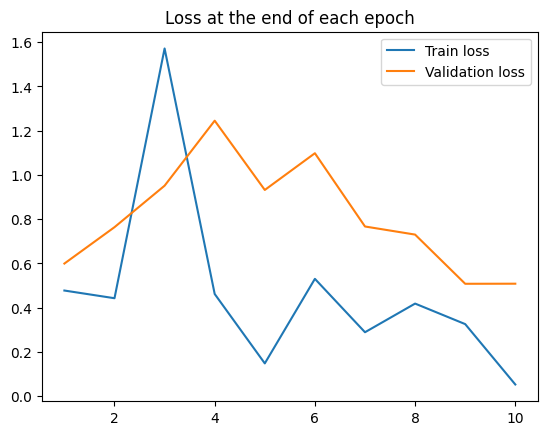

In [27]:
plt.plot(range(1, epochs + 1), train_losses, label="Train loss")
plt.plot(range(1, epochs + 1), test_losses, label="Validation loss")
plt.title("Loss at the end of each epoch")
plt.legend();

In [28]:
max_tst_batch * batch_size

3000

In [29]:
np.array(test_correct)

array([4696, 4921, 5000, 4976, 5037, 5124, 5098, 5116, 5078, 5149],
      dtype=int64)

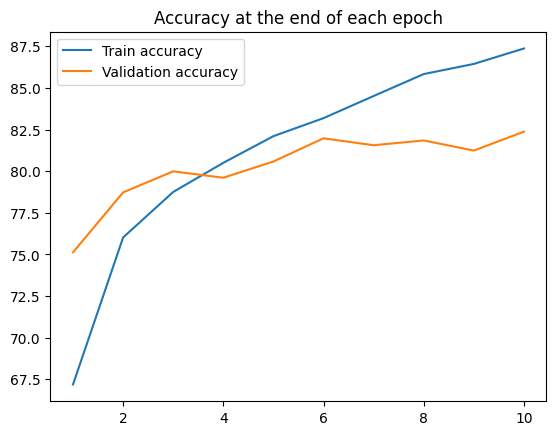

In [30]:
# train_acc = np.array(train_correct) * 100 / max_trn_batch / batch_size
# test_acc = np.array(test_correct) * 100 / max_tst_batch / batch_size

train_acc = np.array(train_correct) * 100 / len(train_data)
test_acc = np.array(test_correct) * 100 / len(test_data)

plt.plot(range(1, epochs + 1), train_acc, label="Train accuracy")
plt.plot(range(1, epochs + 1), test_acc, label="Validation accuracy")
plt.title("Accuracy at the end of each epoch")
plt.legend();